In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

In [2]:
import os

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,2,3")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc
import re
import random
import logging
from collections import Counter

import torch
from rich.console import Console
from rich.theme import Theme
from rich.markup import escape

from src.models import ModelandTokenizer
from src.tokens import prepare_input
from src.goals.functional import apply_chat_template
from src.goals.condition_data import INT_PREDICATES, ConditionSpec, ConditionSample
from src.utils import logging_utils
import transformers

logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)


def rich_print(*a, **k):
    console.print(*a, **k)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")


# MODEL_NAME = "Qwen/Qwen2.5-Coder-14B-Instruct"
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
# MODEL_NAME = "Qwen/Qwen2.5-72B-Instruct"

2026-06-24 15:19:22 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-06-24 15:19:22 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=4, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-06-24 15:19:22 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from transformers import BitsAndBytesConfig

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
    # quantization_config = BitsAndBytesConfig(
    #     load_in_8bit=True
    # )
)
print(f"n_layer={mt.n_layer}, n_heads={mt.model.config.num_attention_heads}")

2026-06-24 15:19:26 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-06-24 15:19:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-24 15:19:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-24 15:19:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-24 15:19:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-24 15:19:26 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-24 15:19:46 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-24 15:19:46 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-24 15:19:47 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_heads=40


# 04.2 · Forced-prefill — does the LM stay on the current variable or move on?

**Setup.** Pick a *target slot* `k` ∈ {`b`,`c`,`d`}. Every **prior** condition (slots `< k`) is force-filled **complete**, as a random mix of single/multi-line impls but with **≥1 multiline** — so the LM has in-context precedent that a variable *may* span multiple lines. The **target** condition is the test variable, forced one of two ways:

- **multiline** — only the *first* (INCOMPLETE) line of a multi-line impl (e.g. `b = int(abs(n) ** 0.5)`). *Hypothesis:* the LM **stays on `b`** to finish it → `continue`.
- **singleline** — one COMPLETE line that fully checks the condition (e.g. `b = n % 2 == 0`). *Hypothesis:* the LM **moves on** to the next var → `moved_on`.

We score `hypothesis_ok = (verdict == expected_verdict)`. Verdict comes from the first assignment statement in the continuation (skips `for`/`if`): `continue` (target var) / `moved_on` (next var) / `other`. `PROMPT_MODE` selects chat vs FIM delivery.

We confirm on `b` first, then `c` and `d` (the per-slot rows in the summary).

In [4]:
# ── prompt preparation — import the SHARED builders (single source of truth) ──
# These are the EXACT functions the scripts use: scripts/clock/sweep_multiline_patch.py and
# train_completion_mask.py construct pairs via src.goals.completion_pairs, which builds prompts
# with src.goals.multiline_prompts.build_example. Importing (not re-defining) them here keeps the
# notebook examining what actually runs — incl. distinct predicate classes (rng.sample) and the
# `naming` arg. The old local copy used rng.choice (could repeat a predicate class) — gone now.
from src.goals.multiline_prompts import (
    MULTILINE_PREDS,
    VAR_LETTERS,
    FIM_PREFIX, FIM_SUFFIX, FIM_MIDDLE,
    build_example,
    result_print,
    replace_in_code_newline_with_tabnewline,
)
print(f"{len(MULTILINE_PREDS)} multiline predicates:", [p.id for p in MULTILINE_PREDS])

19 multiline predicates: ['even', 'odd', 'divisible', 'perfect_square', 'perfect_cube', 'triangular', 'palindrome', 'reversed_greater', 'num_digits_ge', 'set_bits_gt', 'power_of_two', 'coprime_with', 'digit_sum_gt', 'digit_sum_divisible', 'digit_product_gt', 'all_digits_even', 'num_divisors_gt', 'abundant', 'prime']


In [5]:
# ── build the example set: target slot (b/c/d) x target prefill style ──
SEED = 0
N_PER_CELL = 10            # per (slot, style)
SLOTS = [1, 2, 3]          # b, c, d  (target; priors are slots < k, force-filled complete)
STYLES = ["multiline", "singleline"]
PROMPT_MODE = "chat"        # "chat" | "fim"

rng = random.Random(SEED)
examples = [
    build_example(mt=mt, rng=rng, target_slot=k, n_conditions=k + 2, mode=PROMPT_MODE, style=st)
    for k in SLOTS
    for st in STYLES
    for _ in range(N_PER_CELL)
]
print(f"[{PROMPT_MODE}] {len(examples)} examples"
      f"  | style: {dict(Counter(e['prefill_style'] for e in examples))}"
      f"  | target: {dict(Counter(e['target_var'] for e in examples))}")

[chat] 60 examples  | style: {'multiline': 30, 'singleline': 30}  | target: {'b': 20, 'c': 20, 'd': 20}


In [6]:
# ── sanity vis: a multiline (incomplete) and a singleline (complete) prefill, slot 'b' ──
out = []
for st in STYLES:
    EX = [e for e in examples if e["prefill_style"] == st and e["target_slot"] == 1][0]
    if not EX:
        continue
    forced = EX["target_first_line"]
    out += [
        f"[bold]══ {st} ══[/bold]  spec={EX['spec_id']}  mode={EX['mode']}  "
        f"target_var=[cyan]{EX['target_var']}[/cyan]  next_var={EX['next_var']}  "
        f"pred=[magenta]{EX['target_pred']}[/magenta]  expect=[bold]{EX['expected_verdict']}[/bold]",
        f"forced last line: [yellow]{escape(repr(forced))}[/yellow]",
    ]
    for ln in EX["prefill_code"].rstrip("\n").split("\n"):
        if ln.strip() == forced:
            tag = "forced (incomplete)" if st == "multiline" else "forced (complete)"
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]   <- {tag}")
        else:
            out.append(escape(ln))
    out.append("")
rich_print("\n".join(out))

══ multiline ══  spec=ml_s1_mul_424604  mode=chat  target_var=b  next_var=c  pred=digit_sum_divisible  
expect=continue
forced last line: 'b = sum(int(d) for d in str(abs(n)))'
def check_conditions(n: int):
    a = sum(int(d) for d in str(abs(n)))
    a = a > 15
    b = sum(int(d) for d in str(abs(n)))   <- forced (incomplete)

══ singleline ══  spec=ml_s1_sin_615592  mode=chat  target_var=b  next_var=c  pred=perfect_square  expect=moved_on
forced last line: 'b = n >= 0 and int(abs(n) ** 0.5) ** 2 == n'
def check_conditions(n: int):
    a = bin(n).count("1")
    a = n > 0 and a == 1
    b = n >= 0 and int(abs(n) ** 0.5) ** 2 == n   <- forced (complete)

In [7]:
e = EX
print(e["full_prompt"])

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is a power of two
2. n is a perfect square
3. all of n's digits are even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any helper functions.
Do not include any co

## Generate

Greedy, short horizon — we only need the first couple of continuation lines.

In [8]:
# ── batched greedy generation ──
BATCH = 16
MAX_NEW = 64
pad_id = mt.tokenizer.pad_token_id or mt.tokenizer.eos_token_id

# examples = examples[:16]  # TEMP: smaller set for quick iteration while debugging

for i in range(0, len(examples), BATCH):
    chunk = examples[i:i + BATCH]
    inputs = prepare_input(prompts=[e["full_prompt"] for e in chunk], tokenizer=mt)
    plen = inputs["input_ids"].shape[1]
    with torch.no_grad():
        out = mt._model.generate(
            input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
            max_new_tokens=MAX_NEW, do_sample=False, pad_token_id=pad_id,
        )
    for e, row in zip(chunk, out[:, plen:]):
        e["generation"] = mt.tokenizer.decode(row, skip_special_tokens=True)
    del out
    gc.collect(); torch.cuda.empty_cache()
    print(f"{min(i + BATCH, len(examples))}/{len(examples)}")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


16/60
32/60
48/60
60/60


## Behavioral eval

Find the first assignment statement in the continuation (skipping `for`/`if`/blank lines) and
classify by its LHS variable. `=(?!=)` avoids matching `==`/`<=`/`>=`/`!=`.

In [9]:
# ── parse the first assignment in each continuation ──
ASSIGN_RE = re.compile(r"^\s*([A-Za-z_]\w*)\s*(?:\+=|-=|\*=|//=|/=|%=|=(?!=))")


def first_assign(gen):
    for line in gen.split("\n"):
        if not line.strip():
            continue
        m = ASSIGN_RE.match(line)
        if m:
            return m.group(1), line.rstrip()
    return None, None


for e in examples:
    var, line = first_assign(e["generation"])
    e["first_assign_var"] = var
    e["first_assign_line"] = line
    if var == e["target_var"]:
        e["verdict"] = "continue"   # kept evaluating the same variable
    elif var == e["next_var"]:
        e["verdict"] = "moved_on"   # jumped to the next condition
    else:
        e["verdict"] = "other"
    e["hypothesis_ok"] = (e["verdict"] == e["expected_verdict"])
print("verdicts:", Counter(e["verdict"] for e in examples),
      "| hypothesis_ok:", sum(e["hypothesis_ok"] for e in examples), "/", len(examples))

verdicts: Counter({'moved_on': 31, 'continue': 29}) | hypothesis_ok: 59 / 60


In [10]:
# ── summary ──
def pct(a, b):
    return a / b if b else 0.0


n = len(examples)
ok = sum(e["hypothesis_ok"] for e in examples)
print(f"N = {n}   hypothesis_ok = {ok}/{n} = {pct(ok, n):.3f}")

print("\nby prefill style (verdict distribution -> hypothesis):")
for st in STYLES:
    sub = [e for e in examples if e["prefill_style"] == st]
    if not sub:
        continue
    vd = Counter(e["verdict"] for e in sub)
    exp = sub[0]["expected_verdict"]
    s_ok = sum(e["hypothesis_ok"] for e in sub)
    print(f"  {st:11s} (n={len(sub):2d}, expect '{exp}'): "
          f"continue={vd['continue']:2d} moved_on={vd['moved_on']:2d} other={vd['other']:2d}  "
          f"-> hypothesis_ok={s_ok}/{len(sub)} = {pct(s_ok, len(sub)):.3f}")

print("\nby style x target slot (hypothesis_ok):")
for st in STYLES:
    for k in SLOTS:
        sub = [e for e in examples if e["prefill_style"] == st and e["target_slot"] == k]
        if not sub:
            continue
        s_ok = sum(e["hypothesis_ok"] for e in sub)
        print(f"  {st:11s} slot {VAR_LETTERS[k]}: {s_ok:2d}/{len(sub):2d} = {pct(s_ok, len(sub)):.3f}")

print("\nby target predicate (hypothesis_ok):")
for pid in sorted({e["target_pred"] for e in examples}):
    sub = [e for e in examples if e["target_pred"] == pid]
    s_ok = sum(e["hypothesis_ok"] for e in sub)
    print(f"  {pid:22s} {s_ok:2d}/{len(sub):2d}")

viol = [e for e in examples if not e["hypothesis_ok"]]
print(f"\nhypothesis VIOLATIONS ({len(viol)}) — [idx] for the debug cell below:")
for i, e in enumerate(viol):
    rich_print(
        f"  [[red]{i:2d}[/red]] {e['prefill_style']:10s} var={e['target_var']} "
        f"pred={e['target_pred']:20s} verdict={e['verdict']:8s} (exp {e['expected_verdict']:8s}) "
        f"got={e['first_assign_line']!r}"
    )

N = 60   hypothesis_ok = 59/60 = 0.983

by prefill style (verdict distribution -> hypothesis):
  multiline   (n=30, expect 'continue'): continue=29 moved_on= 1 other= 0  -> hypothesis_ok=29/30 = 0.967
  singleline  (n=30, expect 'moved_on'): continue= 0 moved_on=30 other= 0  -> hypothesis_ok=30/30 = 1.000

by style x target slot (hypothesis_ok):
  multiline   slot b: 10/10 = 1.000
  multiline   slot c:  9/10 = 0.900
  multiline   slot d: 10/10 = 1.000
  singleline  slot b: 10/10 = 1.000
  singleline  slot c: 10/10 = 1.000
  singleline  slot d: 10/10 = 1.000

by target predicate (hypothesis_ok):
  abundant                2/ 2
  all_digits_even         4/ 4
  coprime_with            4/ 4
  digit_product_gt        2/ 2
  digit_sum_divisible     7/ 7
  digit_sum_gt            6/ 6
  divisible               3/ 3
  even                    2/ 2
  num_digits_ge           2/ 2
  num_divisors_gt         3/ 3
  odd                     3/ 4
  palindrome              2/ 2
  perfect_cube            

[ 0] multiline  var=c pred=odd                  verdict=moved_on (exp continue) got='    d = len(str(n)) >= 2'

In [12]:
# ── debug ONE hypothesis-violating sample: prompt (target cond + forced prefill marked) + actual vs expected ──
FAIL_IDX = 0   # index from the VIOLATIONS list printed in the summary cell

fails = [
    e for e in examples 
    # if (
    #     not e["hypothesis_ok"] 
    #     and e["target_var"] != "a"
    #     and e["verdict"] == "continue" # moved_on | continue | other
    # )
]
assert fails, "no hypothesis violations 🎉"
e = fails[FAIL_IDX % len(fails)]

out = [
    f"[bold]violation #{FAIL_IDX} / {len(fails)}[/bold]  style=[bold]{e['prefill_style']}[/bold]  "
    f"mode={e['mode']}  verdict=[red]{e['verdict']}[/red] (expected [green]{e['expected_verdict']}[/green])  "
    f"target_var=[cyan]{e['target_var']}[/cyan]  next_var={e['next_var']}  "
    f"pred=[magenta]{e['target_pred']}[/magenta]",
    f"priors (complete, >=1 multiline): {e['prior_styles']}",
    "",
]
if e["mode"] == "fim":
    out.append("[bold]── FIM PREFIX (code up to forced line) ──[/bold]   legend: "
               "[black on green] prefill [/black on green] "
               "[black on yellow] forced target line [/black on yellow]")
    for ln in e["prefill_code"].rstrip("\n").split("\n"):
        if ln.strip() == e["target_first_line"]:
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]")
        else:
            out.append(f"[black on green]{escape(ln)}[/black on green]")
    out += ["", "[bold]── FIM SUFFIX (fixed, model fills the middle before it) ──[/bold]",
            f"[black on magenta]{escape(e['fim_suffix'])}[/black on magenta]"]
else:
    tgt_no = e["target_slot"] + 1
    cond_re = re.compile(rf"^\s*{tgt_no}\.\s")
    prefill_lines = {ln for ln in e["prefill_code"].split("\n") if ln.strip()}
    out.append("[bold]── FULL PROMPT ──[/bold]   legend: "
               "[black on cyan] target condition [/black on cyan] "
               "[black on green] forced prefill [/black on green] "
               "[black on yellow] forced target line [/black on yellow]")
    for ln in e["full_prompt"].split("\n"):
        if cond_re.match(ln):
            out.append(f"[black on cyan]{escape(ln)}[/black on cyan]")
        elif ln.strip() == e["target_first_line"]:
            out.append(f"[black on yellow]{escape(ln)}[/black on yellow]")
        elif ln in prefill_lines:
            out.append(f"[black on green]{escape(ln)}[/black on green]")
        else:
            out.append(f"[dim]{escape(ln)}[/dim]")

if e["prefill_style"] == "singleline":
    exp_txt = f"(condition complete) move on to next var `{e['next_var']} = ...`"
else:
    exp_txt = e["expected_rest"] or "(none)"
out += [
    "",
    "[bold]── GENERATION (actual" + (" = filled middle" if e["mode"] == "fim" else "") + ") ──[/bold]",
    f"[bright_green]{escape(e['generation'])}[/bright_green]",
    "",
    f"[bold]── EXPECTED ({e['expected_verdict']}) ──[/bold]",
    f"[bright_cyan]{escape(exp_txt)}[/bright_cyan]",
    "",
    f"first assignment in generation: {escape(repr(e['first_assign_line']))}  "
    f"(var=[bright_red]{e['first_assign_var']}[/bright_red])",
]
rich_print("\n".join(out))

violation #0 / 60  style=multiline  mode=chat  verdict=continue (expected continue)  target_var=b  next_var=c  
pred=digit_sum_divisible
priors (complete, >=1 multiline): ['multiline']

── FULL PROMPT ──   legend:  target condition   forced prefill   forced target line 
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's digits is greater than 15
2. the sum of n's digits is divisible by 9
3. n is odd

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = sum(int(d) for d in str(abs(n)))
    a = a > 15
    b = sum(int(d) for d in str(abs(n)))


── GENERATION (actual) ──
    b = b % 9 == 0
    c = n % 2 != 0
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, All: {a and b and c}")
</code>

── EXPECTED (continue) ──
    b = b % 9 == 0

first assignment in generation: '    b = b % 9 == 0'  (var=b)

# Causal Experiment

## Test and Debug

In [9]:
from src.tokens import prepare_input
from src.functional import generate_with_patch

source_example = build_example(
    mt=mt,
    rng=random.Random(1234),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="multiline",
)
source_prompt = replace_in_code_newline_with_tabnewline(source_example["full_prompt"]) + '   '
source_tokenized = prepare_input(source_prompt, tokenizer=mt)
source_gen = generate_with_patch(
    mt,
    inputs=source_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=16,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{source_prompt}[/white][plum1]{source_gen}[/plum1]")

destination_example = build_example(
    mt=mt,
    rng=random.Random(4321),
    target_slot=2,
    n_conditions=4,
    mode=PROMPT_MODE,
    style="singleline",
)
destination_prompt = replace_in_code_newline_with_tabnewline(destination_example["full_prompt"]) + '   '
destination_tokenized = prepare_input(destination_prompt, tokenizer=mt)
destination_gen = generate_with_patch(
    mt,
    inputs=destination_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=16,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{destination_prompt}[/white][sea_green3]{destination_gen}[/sea_green3]")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = 1    
    for d in str(abs(n)):    
        a *= int(d)    
    a = a > 0    
    b = int(abs(n) ** 0.5)    
    b = b * b == abs(n)    
    c = n % 

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 2 digits
2. n is odd
3. the sum of n's digits is divisible by 5
4. n is divisible by 5

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n))) >= 2    
    b = n % 2    
    b = b == 1    
    c = sum(int(d) for d in str(abs(n))) % 5 == 0    
    d = n % 5 == 0    
    print(f"Condition 

In [10]:
from src.functional import get_hs, interpret_logits

PATCH_TOK_IDX = [-2]
LAYER_NAME_FORMAT = mt.layer_name_format

METRIC = "logit"
for tok_idx in PATCH_TOK_IDX:
    src_tok = mt.tokenizer.decode(source_tokenized["input_ids"][0, tok_idx].item())
    dst_tok = mt.tokenizer.decode(destination_tokenized["input_ids"][0, tok_idx].item())
    print(f"patch token idx {tok_idx}: source={src_tok!r}  destination={dst_tok!r}")
    if tok_idx != -3:
        assert src_tok == dst_tok, f"patch tokens differ at idx {tok_idx}: {src_tok!r} vs {dst_tok!r}"

# source run
logit_location = (mt.lm_head_name, -1)

source_hs = get_hs(
    mt=mt,
    input=source_tokenized,
    locations=[
        (LAYER_NAME_FORMAT.format(layer_idx), tok_idx)
        for layer_idx in range(mt.n_layer)
        for tok_idx in PATCH_TOK_IDX
    ]
    + [logit_location],
)
source_logits = source_hs[logit_location].squeeze()
src_out = interpret_logits(mt, logits=source_logits)
gold_score = getattr(src_out[0], METRIC)
src_ans = src_out[0].token_id
print(f"source output: {[str(pred) for pred in src_out]}")
print(f"gold score ({mt.tokenizer.decode(src_ans)!r}): {gold_score:.4f}")

# destination run
destination_logits = get_hs(
    mt=mt, input=destination_tokenized, locations=(mt.lm_head_name, -1)
).squeeze()
dst_out, base_track = interpret_logits(
    mt, logits=destination_logits, interested_tokens=(src_ans, )
)
dst_ans = dst_out[0].token_id
print(f"destination output: {[str(pred) for pred in dst_out]}")
base_score = getattr(base_track[src_ans][1], METRIC)
print(f"base score ({mt.tokenizer.decode(src_ans)!r}): {base_score:.4f}")

patch token idx -2: source='    \n'  destination='    \n'
source output: ["' b' [293] (p=0.988, logit=27.000)", "' c' [272] (p=0.011, logit=22.500)", "' if' [421] (p=0.000, logit=14.625)", "' s' [274] (p=0.000, logit=13.375)", "' d' [294] (p=0.000, logit=13.312)"]
gold score (' b'): 27.0000
destination output: ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.750)", "' c' [272] (p=0.000, logit=19.250)", "' D' [422] (p=0.000, logit=16.625)", "' b' [293] (p=0.000, logit=16.250)"]
base score (' b'): 16.2500


In [11]:
from src.functional import get_module_nnsight

module_name = mt.attn_module_name_format.format(40)
with mt.trace(source_tokenized):
    module = get_module_nnsight(mt, module_name)
    out = module.output.save()

out[0].shape

torch.Size([1, 272, 5120])

In [12]:
from src.utils.typing import PathLike, PredictedToken, TokenizerOutput
from src.functional import PatchSpec
from src.trace import get_window, patched_run


def patched_run(
    mt: ModelandTokenizer,
    clean_input: TokenizerOutput,
    patch_hs: dict,
    layer_idx: int,
    layer_name_format: str = mt.layer_name_format,
    window_size: int = 5,
    patch_token_indices: list[int] = [-1]
):
    window = get_window(layer_name_format, layer_idx, window_size, mt.n_layer)
    patches = [
        PatchSpec(
            location=(layer_name, tok_idx),
            patch=patch_hs[(layer_name, tok_idx)],
            strategy="replace",
            on_pass="first",
        )
        for layer_name in window
        for tok_idx in patch_token_indices
    ]
    return get_hs(
        mt=mt,
        input=clean_input,
        locations=logit_location,
        patches=patches,
        return_dict=False,
    ).squeeze()


# smoke test
patched_logits = patched_run(
    mt=mt,
    clean_input=destination_tokenized,
    layer_name_format=LAYER_NAME_FORMAT,
    patch_hs=source_hs,
    layer_idx=40,
    window_size=5,
    patch_token_indices=PATCH_TOK_IDX,
)
patched_out, patched_track = interpret_logits(
    mt,
    logits=patched_logits,
    interested_tokens=(src_ans, dst_ans),
)
print(f"patched output: {[str(pred) for pred in patched_out]}")
patched_score = getattr(patched_track[src_ans][1], METRIC)
print(f"patched score ({mt.tokenizer.decode(src_ans)!r}): {patched_score:.4f}")

patched output: ["' d' [294] (p=0.996, logit=28.500)", "' c' [272] (p=0.004, logit=22.875)", "' e' [384] (p=0.000, logit=18.125)", "' b' [293] (p=0.000, logit=16.750)", "'d' [67] (p=0.000, logit=13.438)"]
patched score (' b'): 16.7500


In [13]:
# sweep over layers

WINDOW_SIZE = 5

track_sweep_scores = {}
for layer_idx in range(0, mt.n_layer, 2):
    patched_logits = patched_run(
        mt=mt,
        clean_input=destination_tokenized,
        patch_hs=source_hs,
        layer_idx=layer_idx,
        window_size=WINDOW_SIZE,
        layer_name_format=LAYER_NAME_FORMAT,
        patch_token_indices=PATCH_TOK_IDX,
    )
    patched_out, patched_track = interpret_logits(
        mt, logits=patched_logits, interested_tokens=(src_ans, dst_out[0].token_id)
    )
    patched_score = getattr(patched_track[src_ans][1], METRIC)
    track_sweep_scores[layer_idx] = patched_track
    indirect_effect = (patched_score - base_score) / (gold_score - base_score)
    print(f"Layer {layer_idx:>3}: IE={indirect_effect:.4f} || {[str(pred) for pred in patched_out]}")

Layer   0: IE=0.0116 || ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.875)", "' c' [272] (p=0.000, logit=19.250)", "' D' [422] (p=0.000, logit=16.625)", "' b' [293] (p=0.000, logit=16.375)"]
Layer   2: IE=0.0116 || ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.750)", "' c' [272] (p=0.000, logit=19.250)", "' D' [422] (p=0.000, logit=16.625)", "' b' [293] (p=0.000, logit=16.375)"]
Layer   4: IE=0.0116 || ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.750)", "' c' [272] (p=0.000, logit=19.250)", "' D' [422] (p=0.000, logit=16.625)", "' b' [293] (p=0.000, logit=16.375)"]
Layer   6: IE=0.0116 || ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.750)", "' c' [272] (p=0.000, logit=19.375)", "' D' [422] (p=0.000, logit=16.625)", "' b' [293] (p=0.000, logit=16.375)"]
Layer   8: IE=0.0116 || ["' d' [294] (p=1.000, logit=33.500)", "' e' [384] (p=0.000, logit=21.625)", "' c' [272] (p=0.000, logit=19.250)", "

### Batched causal sweep — N contrastive pairs × direction × patch-tokens × module × layer

Generalizes the single-pair patch above to `N` pairs and a full config grid, aggregating the
**indirect effect** (`IE = (patched − base) / (gold − base)`) across pairs.

- **Pair** = one *(multiline, singleline)* example built with the **same `target_slot`**; both
  **patch directions** reuse these two prompts, swapping which is source (patched *from*) vs
  destination (patched *into*): `ml→sl` (source=multiline) and `sl→ml` (source=singleline, = the cell above).
- **Validity**: pairs are kept only if src & dst share the token at every patch position and disagree
  on the next-token argmax (a genuine contrast). `target_slot ∈ {1,2,3}` drawn uniformly per pair.
- Varied: **direction** (2), **patch-tokens** `[-1]/[-2]/[-1,-2]` (3), **module/window**
  `residual(3) / mlp(7) / attn(7)` (3), **layer** (swept). **Metrics** `logit` & `prob` are read off
  the *same* patched run.

In [15]:
# ── batched causal sweep · hyperparameters ──────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.functional import get_hs, interpret_logits  # already imported above; explicit for clarity
from src.goals.completion_pairs import LEG_STYLES, build_completion_pairs  # shared w/ train_completion_mask.py

N_PAIRS             = 50
TARGET_SLOT_OPTIONS = [1, 2, 3, 4]       # target slot ∈ {1,2,3,4} (need a prior + a next var)
PAIR_SEED           = 2024
LAYER_STEP          = 2                   # sweep range(0, n_layer, LAYER_STEP)

# ── pairing scheme (mirrors scripts/clock/train_completion_mask.py) ──────────
# SAME=True  -> source IS dest (minimal pair); source_ans == target_ans by construction.
# SAME=False -> source & dest are DIFFERENT contexts. The readout token target_ans is the DEST's
#               OWN flipped-style argmax (NEVER the source's), so source_ans / dst_ans / target_ans
#               can be three distinct tokens. Gated on source_ans != target_ans.
SAME                = False
MATCH_TARGET_SLOT   = False              # (ignored if SAME) force same target_slot on both sides
MATCH_N_COND        = False              # (ignored if SAME) force same n_conditions on both sides
MAX_CONDITIONS      = 6

# PATCH_TOK_OPTIONS   = [(-1,), (-2,), (-2, -1)]
PATCH_TOK_OPTIONS   = [(-2,)]
MODULE_SPECS        = {                   # name -> (layer_name_format, window_size)
    "residual": (mt.layer_name_format,       3),
    # "mlp":      (mt.mlp_module_name_format,  7),
    # "attn":     (mt.attn_module_name_format, 7),
}
DIRECTIONS          = ["ml->sl", "sl->ml"]   # leg: source-donating style -> dest clean (run) style
METRICS             = ["logit", "prob"]
IE_DENOM_EPS        = {"logit": 0.5, "prob": 1e-3}   # mark IE NaN when |gold-base| below this
logit_location      = (mt.lm_head_name, -1)
SWEEP_LAYERS        = list(range(0, mt.n_layer, LAYER_STEP))
needed_pos          = sorted({t for pt in PATCH_TOK_OPTIONS for t in pt})   # e.g. [-2, -1]

n_runs = (N_PAIRS * len(DIRECTIONS) * len(PATCH_TOK_OPTIONS)
          * len(MODULE_SPECS) * len(SWEEP_LAYERS))
print(f"pairing: SAME={SAME}  match_ts={MATCH_TARGET_SLOT}  match_nc={MATCH_N_COND}  "
      f"max_cond={MAX_CONDITIONS}")
print(f"sweep layers ({len(SWEEP_LAYERS)}): {SWEEP_LAYERS}")
print(f"grid / pair: {len(DIRECTIONS)} dir x {len(PATCH_TOK_OPTIONS)} patch-toks "
      f"x {len(MODULE_SPECS)} modules x {len(SWEEP_LAYERS)} layers")
print(f"=> {n_runs} patched forward passes total (both metrics share each run)")

pairing: SAME=False  match_ts=False  match_nc=False  max_cond=6
sweep layers (32): [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62]
grid / pair: 2 dir x 1 patch-toks x 1 modules x 32 layers
=> 3200 patched forward passes total (both metrics share each run)


In [16]:
# ── build & cache N (source, destination) pairs via the SHARED sampler ───────
# Uses src.goals.completion_pairs.build_completion_pairs so this notebook samples EXACTLY what
# scripts/clock/train_completion_mask.py trains on. Each pair's source/dest is a StyledContext
# (the same spec rendered in BOTH styles). We cache per-(context, style) tok + unpatched logits;
# the readout token `target_ans` is the DEST's OWN flipped-style argmax — never the source's.
needed_layers = list(range(mt.n_layer))   # cache ALL layer indices so every window is covered

def _unpatched_logits(tok):
    return get_hs(mt=mt, input=tok, locations=logit_location).float().cpu()

_ctx_cache = {}
def cache_ctx(ctx):
    """Tokenize + cache both styles of one StyledContext (memoized: under SAME, source IS dest)."""
    if id(ctx) in _ctx_cache:
        return _ctx_cache[id(ctx)]
    d = {}
    for style in ("ml", "sl"):
        prompt = ctx.prompt(style)
        tok    = prepare_input(prompt, tokenizer=mt)
        logits = _unpatched_logits(tok)
        d[style] = {"prompt": prompt, "tok": tok, "logits": logits, "argmax": int(logits.argmax())}
        assert d[style]["argmax"] == ctx.ans(style), "notebook vs build argmax mismatch"
    _ctx_cache[id(ctx)] = d
    return d

cps = build_completion_pairs(
    mt, n_pairs=N_PAIRS, target_slots=TARGET_SLOT_OPTIONS, direction="both",
    same=SAME, match_target_slot=MATCH_TARGET_SLOT, match_n_cond=MATCH_N_COND,
    max_conditions=MAX_CONDITIONS, mode=PROMPT_MODE, seed=PAIR_SEED,
    patch_tokens=tuple(needed_pos), log=print,
)
pairs = [{"key": cp.key, "source": cache_ctx(cp.source), "dest": cache_ctx(cp.dest)} for cp in cps]
assert len(pairs) == N_PAIRS, "could not collect enough valid pairs; raise N_PAIRS / loosen gates"
print(f"cached {len(pairs)} pairs  |  unique contexts: {len(_ctx_cache)}  "
      f"(SAME={SAME} -> source IS dest)")

  built 25/50 pairs (33 attempts)
  built 50/50 pairs (69 attempts)
built 50 pairs from 69 attempts
cached 50 pairs  |  unique contexts: 100  (SAME=False -> source IS dest)


In [17]:
# ── qualitative sanity: pair 0 — both contexts' argmaxes + per-leg readout tokens ──
p0 = pairs[0]
def _tok(i):
    return mt.tokenizer.decode(i)

for role in ("source", "dest"):
    for style in ("ml", "sl"):
        ex  = p0[role][style]
        top = interpret_logits(mt, logits=ex["logits"])[0]
        rich_print(f"[bold]{role:6s}/{style}[/bold] next argmax="
                   f"[bold]{escape(repr(_tok(ex['argmax'])))}[/bold] (logit={top.logit:.2f})")

# the three tokens that matter per leg: source_ans (donor), dst_ans (clean), target_ans (dest's
# OWN flipped-style counterfactual — what a successful transplant should produce).
for direction in DIRECTIONS:
    ss = LEG_STYLES[direction]["src_style"]   # source-donating style == dest's target style
    ds = LEG_STYLES[direction]["dst_style"]   # dest's clean (run) style
    source_ans = p0["source"][ss]["argmax"]
    dst_ans    = p0["dest"][ds]["argmax"]
    target_ans = p0["dest"][ss]["argmax"]
    rich_print(f"[cyan]{direction}[/cyan]  source_ans={escape(repr(_tok(source_ans)))}  "
               f"dst_ans={escape(repr(_tok(dst_ans)))}  "
               f"[bold]target_ans={escape(repr(_tok(target_ans)))}[/bold]  "
               f"(all 3 distinct: {len({source_ans, dst_ans, target_ans}) == 3})")
print("shared patch-position tokens (pair 0, ml side):",
      ", ".join(f"{t}:{_tok(p0['source']['ml']['tok']['input_ids'][0, t].item())!r}"
                for t in needed_pos))

source/ml next argmax=' e' (logit=29.38)

source/sl next argmax=' f' (logit=31.38)

dest  /ml next argmax=' c' (logit=26.75)

dest  /sl next argmax=' d' (logit=24.75)

ml->sl  source_ans=' e'  dst_ans=' d'  target_ans=' c'  (all 3 distinct: True)

sl->ml  source_ans=' f'  dst_ans=' c'  target_ans=' d'  (all 3 distinct: True)

shared patch-position tokens (pair 0, ml side): -2:'    \n'


In [18]:
from tqdm.auto import tqdm

# ── main sweep: N pairs x direction x patch-tokens x module x layer ──────────
# Readout is in the DEST's token space: target_ans = dest's flipped-style argmax (its counterfactual
# under the transplanted signal), dst_ans = dest's clean argmax. NEVER the source's answer.
#   gold = dest-as-flipped score for target_ans (ceiling)   base = dest-clean score for target_ans
#   IE   = (patched - base) / (gold - base)
def score_token(logits, token_id, metric):
    if metric == "logit":
        return float(logits[token_id])
    return float(torch.softmax(logits.float(), dim=-1)[token_id])


def capture_source_hs(src_tok):
    """Cache source latents at every (module, layer, patch-pos). One get_hs call PER MODULE keeps
    nnsight reads monotonic by layer (mixing modules -> OutOfOrderError)."""
    src_hs = {}
    for fmt, _ in MODULE_SPECS.values():
        locs = [(fmt.format(L), t) for L in needed_layers for t in needed_pos]
        src_hs.update(get_hs(mt=mt, input=src_tok, locations=locs, return_dict=True))
    return src_hs


records, done = [], 0
for pi, pair in tqdm(enumerate(pairs), total=len(pairs)):
    for direction in DIRECTIONS:
        ss = LEG_STYLES[direction]["src_style"]   # source-donating style (== dest's target style)
        ds = LEG_STYLES[direction]["dst_style"]   # dest's clean (run) style
        src       = pair["source"][ss]            # donor: provides head activations only
        dst_clean = pair["dest"][ds]              # dest, clean style: patched + read out
        dst_flip  = pair["dest"][ss]              # dest, flipped style: counterfactual ceiling
        target_ans = dst_flip["argmax"]           # token we push the dest TOWARD (dest's OWN)  [red]
        dst_ans    = dst_clean["argmax"]          # dest's clean top token                       [green]
        gold     = {m: score_token(dst_flip["logits"],  target_ans, m) for m in METRICS}  # ceiling
        base     = {m: score_token(dst_clean["logits"], target_ans, m) for m in METRICS}  # dst unpatched -> target
        base_dst = {m: score_token(dst_clean["logits"], dst_ans,    m) for m in METRICS}  # dst unpatched -> dst_ans
        src_hs = capture_source_hs(src["tok"])
        for patch_toks in PATCH_TOK_OPTIONS:
            for mod, (fmt, win) in MODULE_SPECS.items():
                for L in SWEEP_LAYERS:
                    patched_logits = (
                        patched_run(
                            mt=mt,
                            clean_input=dst_clean["tok"],
                            patch_hs=src_hs,
                            layer_idx=L,
                            layer_name_format=fmt,
                            window_size=win,
                            patch_token_indices=list(patch_toks),
                        )
                        .float()
                        .cpu()
                    )
                    for m in METRICS:
                        patched     = score_token(patched_logits, target_ans, m)
                        patched_dst = score_token(patched_logits, dst_ans, m)
                        denom = gold[m] - base[m]
                        ie = (
                            (patched - base[m]) / denom
                            if abs(denom) >= IE_DENOM_EPS[m]
                            else float("nan")
                        )
                        records.append(
                            dict(
                                pair=pi,
                                key=pair["key"],
                                direction=direction,
                                patch_tokens=str(list(patch_toks)),
                                module=mod,
                                window=win,
                                layer=L,
                                metric=m,
                                gold=gold[m],
                                base=base[m],
                                base_dst=base_dst[m],
                                patched=patched,        # patched score, target_ans
                                patched_dst=patched_dst,  # patched score, dst_ans
                                ie=ie,
                            )
                        )
                    done += 1
        del src_hs
        gc.collect()
        torch.cuda.empty_cache()
    print(f"pair {pi + 1}/{len(pairs)} done  ({done} patched runs)")

df = pd.DataFrame(records)
print(
    df.shape,
    "rows |",
    int(df["ie"].notna().sum()),
    f"non-NaN IE rows ({df['ie'].isna().mean():.1%} dropped on tiny |gold-base|)",
)

  0%|          | 0/50 [00:00<?, ?it/s]

pair 1/50 done  (64 patched runs)
pair 2/50 done  (128 patched runs)
pair 3/50 done  (192 patched runs)
pair 4/50 done  (256 patched runs)
pair 5/50 done  (320 patched runs)
pair 6/50 done  (384 patched runs)
pair 7/50 done  (448 patched runs)
pair 8/50 done  (512 patched runs)
pair 9/50 done  (576 patched runs)
pair 10/50 done  (640 patched runs)
pair 11/50 done  (704 patched runs)
pair 12/50 done  (768 patched runs)
pair 13/50 done  (832 patched runs)
pair 14/50 done  (896 patched runs)
pair 15/50 done  (960 patched runs)
pair 16/50 done  (1024 patched runs)
pair 17/50 done  (1088 patched runs)
pair 18/50 done  (1152 patched runs)
pair 19/50 done  (1216 patched runs)
pair 20/50 done  (1280 patched runs)
pair 21/50 done  (1344 patched runs)
pair 22/50 done  (1408 patched runs)
pair 23/50 done  (1472 patched runs)
pair 24/50 done  (1536 patched runs)
pair 25/50 done  (1600 patched runs)
pair 26/50 done  (1664 patched runs)
pair 27/50 done  (1728 patched runs)
pair 28/50 done  (1792 pat

In [22]:
# ── aggregate IE across pairs ────────────────────────────────────────────────
def _sem(x):
    x = x.dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0

agg = (df.groupby(["metric", "module", "direction", "patch_tokens", "layer"])
         .agg(ie_mean=("ie", "mean"),  ie_sem=("ie", _sem),  n=("ie", "count"),
              src_mean=("patched", "mean"),      src_sem=("patched", _sem),       # patched score, target_ans
              dst_mean=("patched_dst", "mean"),  dst_sem=("patched_dst", _sem),   # patched score, dst_ans
              base_src=("base", "mean"),         base_dst=("base_dst", "mean"))   # unpatched dst baselines
         .reset_index())

# peak IE (best layer) per config -> drives the direction comparison
agg_valid = agg.dropna(subset=["ie_mean"])
idx  = agg_valid.groupby(["metric", "module", "direction", "patch_tokens"])["ie_mean"].idxmax()
peak = (agg_valid.loc[idx]
        .rename(columns={"layer": "peak_layer", "ie_mean": "peak_ie"})
        [["metric", "module", "direction", "patch_tokens", "peak_layer", "peak_ie", "ie_sem", "n"]]
        .reset_index(drop=True))
print("peak IE (at best layer) per config:")
print(peak.sort_values(["metric", "module", "patch_tokens", "direction"]).to_string(index=False))

peak IE (at best layer) per config:
metric   module direction patch_tokens  peak_layer  peak_ie   ie_sem  n
 logit residual    ml->sl         [-2]          46 0.771449 0.070057 50
 logit residual    sl->ml         [-2]          46 0.532986 0.063969 50
  prob residual    ml->sl         [-2]          46 0.652149 0.067043 50
  prob residual    sl->ml         [-2]          44 0.555068 0.057861 50


In [23]:
df.shape

(6400, 14)

## Load + visualize a saved sweep

Run the batch sweep with `scripts/clock/sweep_multiline_patch.py`, then load its results here
(no model needed) and reuse the **viz** cells below. This cell is self-contained — after running
it you can jump straight to the single-config / direction-comparison plots.

```bash
# small test first
conda run -n goals python scripts/clock/sweep_multiline_patch.py \
    --model Qwen/Qwen2.5-Coder-14B-Instruct --tag small \
    --n-pairs 3 --layer-step 6 --modules residual mlp attn
```

In [5]:
# ── load a saved sweep run (alternative to the live loop above; no model needed) ──
import sys; sys.path.append("../..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scripts.clock.sweep_multiline_patch import load_sweep_results, aggregate_sweep
from src.utils import env_utils

# RUN_DIR = "../../results/multiline_patch/Qwen2.5-1.5B-Instruct/smoke"   # <- point at your run
RUN_DIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multiline_patch", MODEL_NAME.split("/")[-1], 
    "chat_window_n100_step3_seed12345"
)

r = load_sweep_results(RUN_DIR)
df    = r.records
pairs = r.pairs
# config globals the viz cells read, derived from the saved run (so knobs match what was swept):
DIRECTIONS        = r.metadata["directions"]
METRICS           = r.metadata["metrics"]
PATCH_TOK_OPTIONS = [tuple(pt) for pt in r.metadata["patch_tokens"]]
MODULE_SPECS      = {m: (None, w) for m, w in r.metadata["modules"].items()}   # fmt unused for viz

def _sem(x):
    x = x.dropna()
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0

agg = aggregate_sweep(df)
agg_valid = agg.dropna(subset=["ie_mean"])
_idx = agg_valid.groupby(["metric", "module", "direction", "patch_tokens"])["ie_mean"].idxmax()
peak = (agg_valid.loc[_idx]
        .rename(columns={"layer": "peak_layer", "ie_mean": "peak_ie"})
        .reset_index(drop=True))

print(f"loaded {r.metadata['model']} · tag={r.metadata['tag']} · records={df.shape}")
print(f"pairs={len(pairs)} · layers={r.metadata['sweep_layers']} · modules={r.metadata['modules']}")
print(f"patch_tokens={r.metadata['patch_tokens']} · directions={DIRECTIONS} · metrics={METRICS}")
print(f"non-NaN IE: {int(df['ie'].notna().sum())}/{len(df)}  "
      f"({r.metadata['frac_ie_dropped']:.1%} dropped)")
print("-> now run the single-config / direction-comparison viz cells below.")

loaded Qwen/Qwen2.5-72B-Instruct · tag=chat_window_n100_step3_seed12345 · records=(97200, 18)
pairs=100 · layers=[0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51, 54, 57, 60, 63, 66, 69, 72, 75, 78] · modules={'residual': 3, 'mlp': 7, 'attn': 7}
patch_tokens=[[-1], [-2], [-2, -1]] · directions=['ml->sl', 'sl->ml'] · metrics=['logit', 'prob']
non-NaN IE: 96957/97200  (0.2% dropped)
-> now run the single-config / direction-comparison viz cells below.


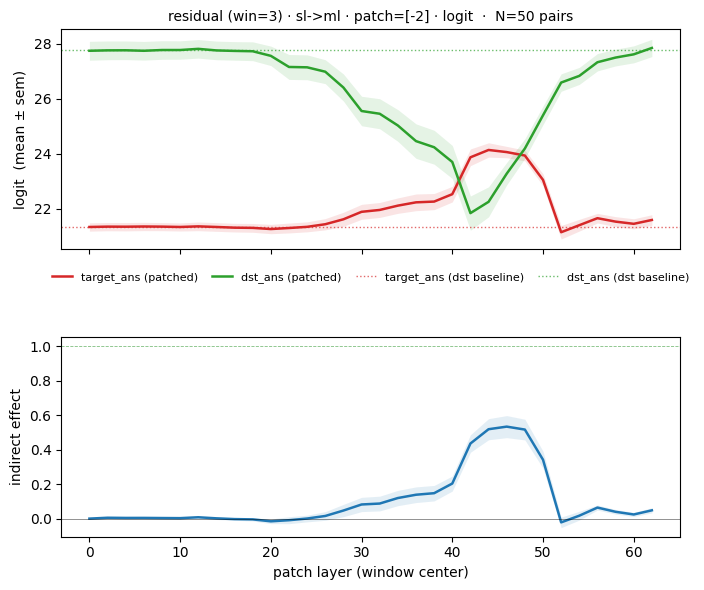

In [28]:
# ── viz · single config: src_ans / dst_ans scores (top) + IE (bottom) ────────
# Pick ONE configuration with the knobs below; only that figure is produced.
SHOW_METRIC = "logit"  # "logit" | "prob"
SHOW_DIRECTION = "sl->ml"  # "ml->sl" | "sl->ml" | "bi" (pool both directions)
SHOW_PATCH_TOKENS = "[-2]"  # one of: "[-1]", "[-2]", "[-2, -1]"
SHOW_MODULE = "residual"  # one of MODULE_SPECS: residual | attn | mlp

# pool over the raw per-pair records so "bi" averages both directions' rows (not means-of-means)
sel_dirs = DIRECTIONS if SHOW_DIRECTION == "bi" else [SHOW_DIRECTION]
d = df[
    (df.metric == SHOW_METRIC)
    & (df.module == SHOW_MODULE)
    & (df.patch_tokens == SHOW_PATCH_TOKENS)
    & (df.direction.isin(sel_dirs))
]
assert not d.empty, "no rows for this config — check the knobs against what was swept"
s = (
    d.groupby("layer")
    .agg(
        src_mean=("patched", "mean"),     src_sem=("patched", _sem),
        dst_mean=("patched_dst", "mean"), dst_sem=("patched_dst", _sem),
        ie_mean=("ie", "mean"),           ie_sem=("ie", _sem),
        base_src=("base", "mean"),        base_dst=("base_dst", "mean"),
    )
    .reset_index()
    .sort_values("layer")
)

win = MODULE_SPECS[SHOW_MODULE][1]
fig, (ax_s, ax_ie) = plt.subplots(
    2, 1, sharex=True, figsize=(7.0, 6.0), gridspec_kw=dict(height_ratios=[1.1, 1.0])
)

# top — patched scores across window centers (src_ans red, dst_ans green) + unpatched baselines
ax_s.plot(s.layer, s.src_mean, "-", color="tab:red", lw=1.8, label="target_ans (patched)")
ax_s.fill_between(
    s.layer,
    s.src_mean - s.src_sem,
    s.src_mean + s.src_sem,
    color="tab:red",
    alpha=0.12,
    lw=0,
)
ax_s.plot(
    s.layer, s.dst_mean, "-", color="tab:green", lw=1.8, label="dst_ans (patched)"
)
ax_s.fill_between(
    s.layer,
    s.dst_mean - s.dst_sem,
    s.dst_mean + s.dst_sem,
    color="tab:green",
    alpha=0.12,
    lw=0,
)
ax_s.axhline(
    s.base_src.iloc[0],
    color="tab:red",
    ls=":",
    lw=1.0,
    alpha=0.7,
    label="target_ans (dst baseline)",
)
ax_s.axhline(
    s.base_dst.iloc[0],
    color="tab:green",
    ls=":",
    lw=1.0,
    alpha=0.7,
    label="dst_ans (dst baseline)",
)
ax_s.set_ylabel(f"{SHOW_METRIC}  (mean ± sem)")
ax_s.set_title(
    f"{SHOW_MODULE} (win={win}) · {SHOW_DIRECTION} · patch={SHOW_PATCH_TOKENS} · "
    f"{SHOW_METRIC}  ·  N={len(pairs)} pairs",
    fontsize=10,
)
# legend is drawn below this panel (single row, 4 cols) after layout — see end of cell

# bottom — indirect effect for the same config
ax_ie.plot(s.layer, s.ie_mean, "-", color="tab:blue", lw=1.8)
ax_ie.fill_between(
    s.layer,
    s.ie_mean - s.ie_sem,
    s.ie_mean + s.ie_sem,
    color="tab:blue",
    alpha=0.12,
    lw=0,
)
ax_ie.axhline(0, color="k", lw=0.6, alpha=0.5)
ax_ie.axhline(1, color="green", lw=0.6, ls="--", alpha=0.5)
ax_ie.set_ylabel("indirect effect")
ax_ie.set_xlabel("patch layer (window center)")

fig.tight_layout()
fig.subplots_adjust(hspace=0.42)  # open a gap between the panels to hold the legend
# legend below the top panel: single row, 4 columns, sitting above the IE plot
ax_s.legend(
    fontsize=8,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    frameon=False,
    columnspacing=1.3,
    handlelength=1.8,
)
plt.show()

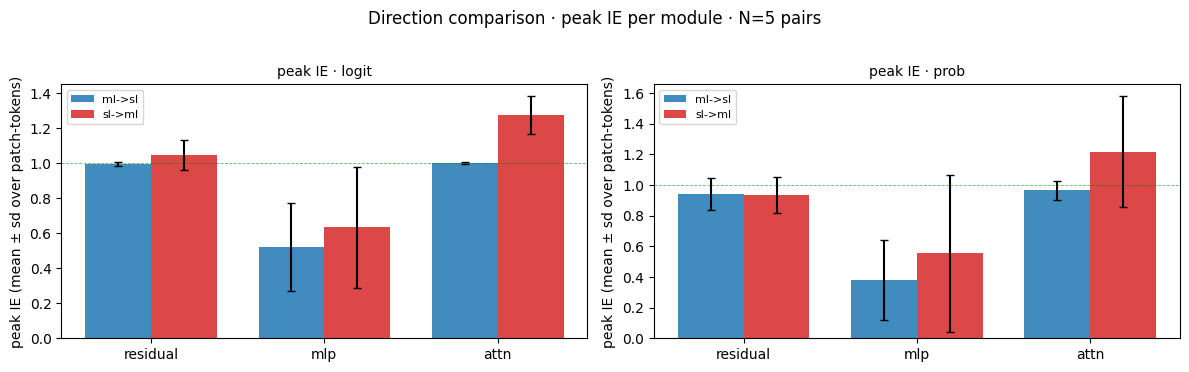


direction summary — mean peak IE over modules & patch-tokens:
direction    ml->sl    sl->ml
metric                       
logit      0.838968  0.985594
prob       0.761401  0.900495


In [6]:
# ── viz 2 · direction comparison: peak IE per module (mean ± sd over patch-tokens) ──
modules = list(MODULE_SPECS)
dir_colors = {"ml->sl": "tab:blue", "sl->ml": "tab:red"}
fig, axes = plt.subplots(1, len(METRICS), squeeze=False, figsize=(6.0 * len(METRICS), 3.6))
xpos, w = np.arange(len(modules)), 0.38
for c, metric in enumerate(METRICS):
    ax = axes[0][c]
    for di, direction in enumerate(DIRECTIONS):
        means, errs = [], []
        for mod in modules:
            vals = peak[(peak.metric == metric) & (peak.module == mod)
                        & (peak.direction == direction)]["peak_ie"]
            means.append(vals.mean())
            errs.append(vals.std(ddof=1) if len(vals) > 1 else 0.0)
        ax.bar(xpos + (di - 0.5) * w, means, w, yerr=errs, capsize=3,
               color=dir_colors[direction], label=direction, alpha=0.85)
    ax.set_xticks(xpos); ax.set_xticklabels(modules)
    ax.axhline(0, color="k", lw=0.6)
    ax.axhline(1, color="green", ls="--", lw=0.6, alpha=0.6)
    ax.set_title(f"peak IE · {metric}", fontsize=10)
    ax.set_ylabel("peak IE (mean ± sd over patch-tokens)")
    ax.legend(fontsize=8)
fig.suptitle(f"Direction comparison · peak IE per module · N={len(pairs)} pairs", y=1.02)
fig.tight_layout()
plt.show()

print("\ndirection summary — mean peak IE over modules & patch-tokens:")
print(peak.groupby(["metric", "direction"])["peak_ie"].mean().unstack().to_string())

# Gaze Heads

In [41]:
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
VERSION = "conditions"
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-100 gaze heads  (compare_with='mean', q_span=15)  score range [2.725, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 85 more)


In [51]:
from src.tokens import prepare_input
from src.functional import generate_with_patch

source_example = build_example(
    mt=mt,
    rng=random.Random(12345),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="multiline",
)
source_prompt = replace_in_code_newline_with_tabnewline(source_example["full_prompt"]) + '   '
source_tokenized = prepare_input(source_prompt, tokenizer=mt)
source_gen = generate_with_patch(
    mt,
    inputs=source_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{source_prompt}[/white][plum1]{source_gen}[/plum1]")

destination_example = build_example(
    mt=mt,
    rng=random.Random(54321),
    target_slot=1,
    n_conditions=3,
    mode=PROMPT_MODE,
    style="singleline",
)
destination_prompt = replace_in_code_newline_with_tabnewline(destination_example["full_prompt"]) + '   '
destination_tokenized = prepare_input(destination_prompt, tokenizer=mt)
destination_gen = generate_with_patch(
    mt,
    inputs=destination_tokenized,
    n_gen_per_prompt=1,
    max_new_tokens=32,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(f"[white]{destination_prompt}[/white][sea_green3]{destination_gen}[/sea_green3]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's digits is divisible by 5
2. n is even
3. n has more than 2 ones in its binary representation

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = sum(int(d) for d in str(abs(n)))    
    a = a % 5 == 0    
    b = n % 2    
    b = b == 0    
    c = bin(n).count('1')    
    c = c > 2    
    print(f"Condition 

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. all of n's digits are even
2. n is divisible by 7
3. n is smaller than the number obtained by reversing its digits

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a =     
    a = all(d % 2 == 0 for d in a)    
    b = n % 7 == 0    
    c = n < int(str(n)[::-1])    
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 

In [53]:
from src.attention import get_attention_matrices, show_interactive_attention

value_weighted = True
# full_prompt = source_prompt + source_gen
full_prompt = destination_prompt + destination_gen

attn_info = get_attention_matrices(
    input = full_prompt,
    mt = mt,
    value_weighted = value_weighted,
)

# selected_heads = sorted(goalscope_heads)  # or gaze_heads
selected_heads = sorted(gaze_heads)  # or goalscope_heads
show_interactive_attention(
    attn_info=attn_info,
    selected_heads=selected_heads,
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"{len(selected_heads)} selected heads ({value_weighted=})",
    height=None,
)

'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>100 selected heads (value_weighted=True)</title>\n<style>\n #iaviz-17aa7d71 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-17aa7d71 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-17aa7d71 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-17aa7d71 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-17aa7d71 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-17aa7d71 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n   bord